# 02.7 - End-to-End Visual Speech Recognition Dataset Preprocessing Pipeline
## Video Frame Extraction → Dlib Method D (96×96 Letterboxed) Cropping → Zero-Leakage 78/20 Augmentation → Automated `data/processed/` Mount
### Tai Phake Visual Speech Recognition (VSR) Project

---

### Strategic Purpose & Unified Single-File Workflow
This notebook provides a complete, autonomous, and self-contained data pipeline for the Tai Phake VSR dataset. Whenever speaker videos are added, modified, or replaced (such as replacing low-performing validation speakers `s26` and `s28` with clean speakers **`s43`** and **`s45`**), simply run this single notebook to execute the entire end-to-end transformation:

1. **Video Ingestion & Verification**: Scans video files (`.mp4`) across all 11 digits (`d0` through `d10`) from `data/experiments/digit_videos_only/`.
2. **Sequential Frame Extraction**: Decodes video streams into sequential high-quality JPEG frames (`frame_0001.jpg` … `frame_XXXX.jpg`).
3. **Dlib Facial Landmark Detection & Tracking**: Employs Dlib's 68-point shape predictor to track lip contours (landmarks 48–67) across all utterances with inter-frame temporal tracking and fallback.
4. **Method D Aspect-Preserving Letterboxed Cropping (96x96)**: Isolates the mouth bounding box with fixed margin padding (Px=15px, Py=10px), scales proportionally without aspect distortion, and letterboxes onto a neutral black 96x96 canvas.
5. **Conservative Lip-Reading Safe Augmentation**: Expands the dataset to **98 folders** (78 Train + 20 Val) using sequence-consistent geometric transforms (±3 degrees, ±3 px) and photometric variations with reflection border padding.
6. **Zero-Leakage Automated `data/processed/` Mount**: Refreshes symlinks inside `data/processed/train` (78 folders) and `data/processed/val` (20 folders) with strict assertion verification so that model training can start immediately.
7. **Verification & Diagnostics**: Emits manifests, geometry logs, and a high-resolution sample preview grid.

## 1. Centralized User Configuration & Paths
Adjust the variables below whenever folder names, dataset locations, or speaker splits change.

In [1]:
# Section 1: Centralized Configuration & Environment Setup
import os
import sys
import re
import json
import time
import shutil
import hashlib
import random
import threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from typing import Dict, List, Tuple, Optional, Any

import cv2
import dlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ==============================================================================
# 1. USER CONFIGURATION: FOLDER NAMES & PATHS
# ==============================================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"

# Master Video Source Directory
VIDEO_INPUT_DIR = DATA_ROOT / "experiments" / "digit_videos_only"

# Raw Frames Extraction Cache Directory
EXTRACTED_RAW_FRAMES_DIR = DATA_ROOT / "experiments" / "extracted_raw_frames_replaced_s26_s28"

# Output Cropped Dataset Name & Flat Storage Directory
DATASET_NAME = "dlib_aug_cropd_98_78_20_96x96_replaced_s26_s28"
OUTPUT_DATASET_DIR = DATA_ROOT / "experiments" / DATASET_NAME

# Results & Diagnostic Artifacts Directory
RESULTS_DIR = PROJECT_ROOT / "results" / DATASET_NAME

# Dlib 68-Point Facial Landmark Model File
DLIB_PREDICTOR_PATH = PROJECT_ROOT / "models" / "dlib" / "shape_predictor_68_face_landmarks.dat"

# Active Model Training Ingestion Directory (symlinks mounted here)
PROCESSED_DIR = DATA_ROOT / "processed"

# ==============================================================================
# 2. SPEAKER PARTITION (22 Train, 6 Val = 28 Base Speakers)
# Note: s26 and s28 removed; s43 and s45 added as new clean validation speakers
# ==============================================================================
TRAIN_BASE_SPEAKERS = [f"s{i}" for i in range(1, 23)]  # s1 through s22 (22 base speakers)
VAL_BASE_SPEAKERS = ["s23", "s24", "s25", "s30", "s43", "s45"]  # 6 base speakers

# Target Directory Expansion Numbers
TARGET_TRAIN_FOLDERS = 78
TARGET_VAL_FOLDERS = 20
TOTAL_TARGET_FOLDERS = TARGET_TRAIN_FOLDERS + TARGET_VAL_FOLDERS  # 98 Folders

# Validation speakers designated for 4-folder expansion (1 orig + 3 aug = 4)
# 2 spk x 4 folders + 4 spk x 3 folders = 20 folders
VAL_FOUR_FOLDER_SPEAKERS = ["s25", "s43"]

# Method D Letterbox Cropping Parameters
TARGET_WIDTH = 96
TARGET_HEIGHT = 96
PADDING_X = 15      # Horizontal margin in px
PADDING_Y = 10      # Vertical margin in px
BORDER_VALUE = 0    # Black letterbox canvas background
JPEG_QUALITY = 95

# Execution Controls
FORCE_REEXTRACT_FRAMES = False   # Set True to overwrite cached raw frames
NUM_WORKERS = min(8, os.cpu_count() or 4)

print("=" * 80)
print("TAI PHAKE VSR: END-TO-END DATASET PIPELINE CONFIGURATION")
print("=" * 80)
print(f"Project Root             : {PROJECT_ROOT}")
print(f"Video Input Source       : {VIDEO_INPUT_DIR}")
print(f"Extracted Raw Frames Dir : {EXTRACTED_RAW_FRAMES_DIR}")
print(f"Output Dataset Directory : {OUTPUT_DATASET_DIR}")
print(f"Results Directory        : {RESULTS_DIR}")
print(f"Processed Mount Dir      : {PROCESSED_DIR}")
print(f"Train Base Speakers ({len(TRAIN_BASE_SPEAKERS):2d}) : {TRAIN_BASE_SPEAKERS}")
print(f"Val Base Speakers   ({len(VAL_BASE_SPEAKERS):2d}) : {VAL_BASE_SPEAKERS}")
print(f"Target Folders           : {TARGET_TRAIN_FOLDERS} Train + {TARGET_VAL_FOLDERS} Val = {TOTAL_TARGET_FOLDERS} Total")
print(f"Dlib Model File          : {DLIB_PREDICTOR_PATH}")
print(f"Crop Resolution          : {TARGET_WIDTH}x{TARGET_HEIGHT} (Method D Letterbox)")
print("=" * 80)


TAI PHAKE VSR: END-TO-END DATASET PIPELINE CONFIGURATION
Project Root             : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading
Video Input Source       : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/digit_videos_only
Extracted Raw Frames Dir : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/extracted_raw_frames_replaced_s26_s28
Output Dataset Directory : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/experiments/dlib_aug_cropd_98_78_20_96x96_replaced_s26_s28
Results Directory        : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/dlib_aug_cropd_98_78_20_96x96_replaced_s26_s28
Processed Mount Dir      : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed
Train Base Speakers (22) : ['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 's22']
Val Ba

/Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Zero-Leakage 78/20 Speaker Allocation & Folder Mapping
Maps each base speaker to their designated original and augmented folder variants (`sX`, `sX_aug1`, `sX_aug2`, `sX_aug3`), verifying exact total folder counts and strict zero data leakage.

In [2]:
# Section 2: Speaker Partition Allocation
def natural_sort_key(s: str) -> int:
    m = re.search(r"\d+", s)
    return int(m.group(0)) if m else 0

def build_speaker_folder_mapping(
    base_speakers: List[str],
    target_count: int,
    prefix_aug: str = "aug",
    custom_four_folders: Optional[List[str]] = None
) -> Dict[str, List[str]]:
    n_base = len(base_speakers)
    assert target_count >= n_base, f"Target count {target_count} < base speakers {n_base}"
    extra_folders_needed = target_count - n_base
    base_augs_per_spk = extra_folders_needed // n_base
    remainder = extra_folders_needed % n_base

    mapping = {}
    four_folder_set = set(custom_four_folders) if custom_four_folders else set()

    for idx, spk in enumerate(base_speakers):
        dirs = [spk]
        if custom_four_folders is not None:
            num_augs = base_augs_per_spk + (1 if spk in four_folder_set else 0)
        else:
            num_augs = base_augs_per_spk + (1 if idx < remainder else 0)

        for a_idx in range(1, num_augs + 1):
            dirs.append(f"{spk}_{prefix_aug}{a_idx}")
        mapping[spk] = dirs

    total_dirs = sum(len(v) for v in mapping.values())
    assert total_dirs == target_count, f"Generated {total_dirs} != target {target_count}"
    return mapping

# Build mappings for Train and Validation sets
train_mapping = build_speaker_folder_mapping(TRAIN_BASE_SPEAKERS, TARGET_TRAIN_FOLDERS)
val_mapping = build_speaker_folder_mapping(
    VAL_BASE_SPEAKERS,
    TARGET_VAL_FOLDERS,
    custom_four_folders=VAL_FOUR_FOLDER_SPEAKERS
)

all_train_folders = sorted([f for dirs in train_mapping.values() for f in dirs], key=natural_sort_key)
all_val_folders = sorted([f for dirs in val_mapping.values() for f in dirs], key=natural_sort_key)
all_98_folders = sorted(all_train_folders + all_val_folders, key=natural_sort_key)

# Assertions for rigorous split integrity
overlap = set(TRAIN_BASE_SPEAKERS) & set(VAL_BASE_SPEAKERS)
assert len(overlap) == 0, f"CRITICAL LEAKAGE DETECTED: Overlap {overlap}"
assert len(all_train_folders) == TARGET_TRAIN_FOLDERS, f"Train folder count mismatch: {len(all_train_folders)} != {TARGET_TRAIN_FOLDERS}"
assert len(all_val_folders) == TARGET_VAL_FOLDERS, f"Val folder count mismatch: {len(all_val_folders)} != {TARGET_VAL_FOLDERS}"
assert len(all_98_folders) == TOTAL_TARGET_FOLDERS, f"Total folder count mismatch: {len(all_98_folders)} != {TOTAL_TARGET_FOLDERS}"

print("=" * 80)
print("SPEAKER ALLOCATION & ZERO-LEAKAGE VERIFICATION")
print("=" * 80)
print(f"Train Base Speakers ({len(TRAIN_BASE_SPEAKERS)}): {TRAIN_BASE_SPEAKERS}")
print(f"Train Folders       ({len(all_train_folders)}): 12 spk x 4 ({TRAIN_BASE_SPEAKERS[:12]}) + 10 spk x 3 ({TRAIN_BASE_SPEAKERS[12:]})")
print(f"Val Base Speakers   ({len(VAL_BASE_SPEAKERS)}): {VAL_BASE_SPEAKERS}")
print(f"Val Folders         ({len(all_val_folders)}): 2 spk x 4 ({VAL_FOUR_FOLDER_SPEAKERS}) + 4 spk x 3 ({[s for s in VAL_BASE_SPEAKERS if s not in VAL_FOUR_FOLDER_SPEAKERS]})")
print(f"Total Folders       ({len(all_98_folders)}): exactly {TOTAL_TARGET_FOLDERS} directories")
print("[SUCCESS] Zero-leakage verified: No overlap between Train and Val sets!")
print("=" * 80)


SPEAKER ALLOCATION & ZERO-LEAKAGE VERIFICATION
Train Base Speakers (22): ['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 's22']
Train Folders       (78): 12 spk x 4 (['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12']) + 10 spk x 3 (['s13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 's22'])
Val Base Speakers   (6): ['s23', 's24', 's25', 's30', 's43', 's45']
Val Folders         (20): 2 spk x 4 (['s25', 's43']) + 4 spk x 3 (['s23', 's24', 's30', 's45'])
Total Folders       (98): exactly 98 directories
[SUCCESS] Zero-leakage verified: No overlap between Train and Val sets!


## 3. Video Frame Extraction
Scans all digit clips (`d0` through `d10`) for each target speaker in `VIDEO_INPUT_DIR`, extracts sequential JPEG frames, and writes an extraction audit report.

In [3]:
# Section 3: Sequential Video Frame Extraction
def extract_video_frames(
    speaker: str,
    digit: str,
    video_path: Path,
    out_dir: Path,
    save_quality: int = JPEG_QUALITY,
    force_reextract: bool = FORCE_REEXTRACT_FRAMES
) -> Dict[str, Any]:
    out_dir.mkdir(parents=True, exist_ok=True)
    existing_frames = list(out_dir.glob("*.jpg"))

    if not force_reextract and len(existing_frames) > 0:
        return {
            "speaker": speaker,
            "digit": digit,
            "video_path": str(video_path),
            "status": "CACHED",
            "extracted_count": len(existing_frames),
            "error": None
        }

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return {
            "speaker": speaker,
            "digit": digit,
            "video_path": str(video_path),
            "status": "FAILED",
            "extracted_count": 0,
            "error": "Failed to open video file"
        }

    frame_count = 0
    while True:
        ret, frame = cap.read()
        if not ret or frame is None:
            break
        frame_count += 1
        out_path = out_dir / f"frame_{frame_count:04d}.jpg"
        cv2.imwrite(str(out_path), frame, [int(cv2.IMWRITE_JPEG_QUALITY), save_quality])
    cap.release()

    return {
        "speaker": speaker,
        "digit": digit,
        "video_path": str(video_path),
        "status": "SUCCESS" if frame_count > 0 else "FAILED",
        "extracted_count": frame_count,
        "error": None if frame_count > 0 else "Zero frames decoded"
    }

all_target_base_speakers = sorted(TRAIN_BASE_SPEAKERS + VAL_BASE_SPEAKERS, key=natural_sort_key)
extraction_tasks = []

for spk in all_target_base_speakers:
    spk_video_dir = VIDEO_INPUT_DIR / spk
    if not spk_video_dir.exists():
        print(f"[Warning] Speaker directory missing: {spk_video_dir}")
        continue
    for d_idx in range(11):
        dig = f"d{d_idx}"
        dig_dir = spk_video_dir / dig
        if not dig_dir.exists():
            continue
        mp4s = sorted([f for f in dig_dir.iterdir() if f.suffix.lower() == ".mp4" and not f.name.startswith(".")])
        if not mp4s:
            continue
        target_vid = next((v for v in mp4s if v.name == f"{dig}.mp4"), mp4s[0])
        raw_out_dir = EXTRACTED_RAW_FRAMES_DIR / spk / dig
        extraction_tasks.append((spk, dig, target_vid, raw_out_dir))

print(f"Total video clips identified: {len(extraction_tasks)}")

extraction_results = []
for spk, dig, vid, out_dir in tqdm(extraction_tasks, desc="Extracting Video Frames"):
    res = extract_video_frames(spk, dig, vid, out_dir)
    extraction_results.append(res)

df_extract = pd.DataFrame(extraction_results)
EXTRACTED_RAW_FRAMES_DIR.mkdir(parents=True, exist_ok=True)
df_extract.to_csv(EXTRACTED_RAW_FRAMES_DIR / "extraction_report.csv", index=False)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_extract.to_csv(RESULTS_DIR / "extraction_report.csv", index=False)

print("\n" + "=" * 80)
print("FRAME EXTRACTION AUDIT SUMMARY")
print("=" * 80)
print(f"Total Clips Processed  : {len(df_extract)}")
print(f"Successful / Cached    : {((df_extract['status'] == 'SUCCESS') | (df_extract['status'] == 'CACHED')).sum()}")
print(f"Failed Clips           : {(df_extract['status'] == 'FAILED').sum()}")
print(f"Total Raw Frames Ready : {df_extract['extracted_count'].sum():,}")
print("=" * 80)


Total video clips identified: 308


Extracting Video Frames: 100%|██████████| 308/308 [00:37<00:00,  8.20it/s]


FRAME EXTRACTION AUDIT SUMMARY
Total Clips Processed  : 308
Successful / Cached    : 308
Failed Clips           : 0
Total Raw Frames Ready : 12,921


## 4. Dlib 68-Point Facial Landmarks & Method D (96×96 Letterbox) Cropping
Localizes the mouth region (Dlib landmarks 48–67) with horizontal and vertical padding margins ($P_x=15\text{ px}, P_y=10\text{ px}$), scales proportionally without vertical squishing, and letterboxes onto a neutral black $96 \times 96$ canvas.

In [4]:
# Section 4: Dlib Landmark Localization & Method D Cropping Engine
_THREAD_LOCAL = threading.local()

def get_dlib_models(predictor_path: Path):
    if not hasattr(_THREAD_LOCAL, "detector"):
        _THREAD_LOCAL.detector = dlib.get_frontal_face_detector()
        _THREAD_LOCAL.predictor = dlib.shape_predictor(str(predictor_path))
    return _THREAD_LOCAL.detector, _THREAD_LOCAL.predictor

def extract_method_d_crop(
    img: np.ndarray,
    center_x: float,
    center_y: float,
    raw_width: float,
    raw_height: float,
    pad_x: int = PADDING_X,
    pad_y: int = PADDING_Y,
    canvas_size: int = TARGET_WIDTH,
    border_val: int = BORDER_VALUE
) -> Tuple[np.ndarray, int, int, int, int]:
    h_img, w_img = img.shape[:2]
    min_x = center_x - raw_width / 2.0
    max_x = center_x + raw_width / 2.0
    min_y = center_y - raw_height / 2.0
    max_y = center_y + raw_height / 2.0

    x1 = max(0, int(round(min_x - pad_x)))
    y1 = max(0, int(round(min_y - pad_y)))
    x2 = min(w_img, int(round(max_x + pad_x)))
    y2 = min(h_img, int(round(max_y + pad_y)))

    roi = img[y1:y2, x1:x2]
    h_roi, w_roi = roi.shape[:2]
    if h_roi == 0 or w_roi == 0:
        return np.full((canvas_size, canvas_size, 3), border_val, dtype=np.uint8), 0, 0, 0, 0

    scale = canvas_size / max(w_roi, h_roi)
    new_w = min(canvas_size, max(1, int(round(w_roi * scale))))
    new_h = min(canvas_size, max(1, int(round(h_roi * scale))))
    resized_roi = cv2.resize(roi, (new_w, new_h), interpolation=cv2.INTER_AREA)

    canvas = np.full((canvas_size, canvas_size, 3), border_val, dtype=np.uint8)
    offset_x = (canvas_size - new_w) // 2
    offset_y = (canvas_size - new_h) // 2
    canvas[offset_y:offset_y + new_h, offset_x:offset_x + new_w] = resized_roi
    return canvas, new_w, new_h, canvas_size - new_w, canvas_size - new_h

print("Method D Letterbox cropping engine ready.")


Method D Letterbox cropping engine ready.


## 5. Lip-Reading Safe Conservative Data Augmentation
Performs sequence-level geometric sampling (fixed $\Delta x, \Delta y, \theta, s$ across all frames of an utterance variant) and photometric augmentations with reflection borders.

In [5]:
# Section 5: Conservative Augmentation Functions
def get_geometric_rng(base_seed: int, speaker: str, digit: str, variant_idx: int) -> np.random.Generator:
    key = f"{base_seed}_{speaker}_{digit}_aug{variant_idx}_geom".encode("utf-8")
    return np.random.default_rng(int.from_bytes(hashlib.sha256(key).digest()[:4], byteorder="little"))

def get_photometric_rng(base_seed: int, speaker: str, digit: str, frame: str, variant_idx: int) -> np.random.Generator:
    key = f"{base_seed}_{speaker}_{digit}_{frame}_aug{variant_idx}_photo".encode("utf-8")
    return np.random.default_rng(int.from_bytes(hashlib.sha256(key).digest()[:4], byteorder="little"))

def sample_geometric_transform(rng: np.random.Generator, width: int = TARGET_WIDTH, height: int = TARGET_HEIGHT) -> np.ndarray:
    tx = float(rng.uniform(-3.0, 3.0))
    ty = float(rng.uniform(-3.0, 3.0))
    angle = float(rng.uniform(-3.0, 3.0))
    scale = float(rng.uniform(0.97, 1.03))
    M = cv2.getRotationMatrix2D((width / 2.0, height / 2.0), angle, scale)
    M[0, 2] += tx
    M[1, 2] += ty
    return M

def apply_conservative_augmentation(img: np.ndarray, M: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    h, w = img.shape[:2]
    # 1. Geometric warp with reflection border
    transformed = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    # 2. Photometric: Contrast (0.92 - 1.08) and Brightness (-10 to +10)
    alpha = float(rng.uniform(0.92, 1.08))
    beta = float(rng.uniform(-10.0, 10.0))
    photo = np.clip(alpha * transformed.astype(np.float32) + beta, 0.0, 255.0).astype(np.uint8)
    # 3. Gaussian sensor noise (50% prob)
    if rng.random() < 0.50:
        sigma = float(rng.uniform(1.0, 3.5))
        photo = np.clip(photo.astype(np.float32) + rng.normal(0.0, sigma, photo.shape), 0.0, 255.0).astype(np.uint8)
    # 4. Mild Gaussian blur (30% prob)
    if rng.random() < 0.30:
        photo = cv2.GaussianBlur(photo, (3, 3), 0.5)
    return photo

print("Augmentation parameters loaded.")


Augmentation parameters loaded.


## 6. End-to-End Cropping & 98-Folder Augmentation Execution
Processes all speakers, executes landmark localization, saves clean original Method D crops, and generates augmented variants directly into `OUTPUT_DATASET_DIR`.

In [6]:
# Section 6: End-to-End Cropping & Augmentation Execution
def process_single_speaker(args: Tuple[str, List[str], str]) -> Dict[str, Any]:
    base_speaker, target_folders, split_name = args
    raw_spk_dir = EXTRACTED_RAW_FRAMES_DIR / base_speaker
    manifest_records = []
    geom_records = []

    if not raw_spk_dir.exists():
        return {"status": "SKIPPED_NO_RAW_DIR", "manifest_records": [], "geom_records": []}

    digit_dirs = sorted([d for d in raw_spk_dir.iterdir() if d.is_dir() and not d.name.startswith(".")], key=lambda x: natural_sort_key(x.name))
    aug_variants = [f for f in target_folders if f != base_speaker]

    # Sample geometric transforms per (digit, variant)
    geo_transforms = {}
    for dig_dir in digit_dirs:
        dig = dig_dir.name
        for v_folder in aug_variants:
            m = re.search(r"aug(\d+)", v_folder)
            v_idx = int(m.group(1)) if m else 1
            geo_rng = get_geometric_rng(SEED, base_speaker, dig, v_idx)
            geo_transforms[(dig, v_folder)] = sample_geometric_transform(geo_rng, TARGET_WIDTH, TARGET_HEIGHT)

    detector, predictor = get_dlib_models(DLIB_PREDICTOR_PATH)

    for dig_dir in digit_dirs:
        dig = dig_dir.name
        frames = sorted([f for f in dig_dir.glob("*.jpg") if not f.name.startswith(".")], key=lambda x: natural_sort_key(x.name))
        if not frames:
            continue

        last_rect = None
        last_geom = None

        for fpath in frames:
            fname = fpath.name
            raw_img = cv2.imread(str(fpath))
            if raw_img is None:
                continue

            # 1. Landmark detection
            gray = cv2.cvtColor(raw_img, cv2.COLOR_BGR2GRAY)
            faces = detector(gray, 0)
            rect = faces[0] if faces else last_rect
            if faces:
                last_rect = rect

            geom = None
            if rect is not None:
                try:
                    shape = predictor(gray, rect)
                    pts = np.array([[shape.part(i).x, shape.part(i).y] for i in range(48, 68)], dtype=np.float32)
                    min_x, min_y = pts.min(axis=0)
                    max_x, max_y = pts.max(axis=0)
                    geom = {
                        "center_x": float((min_x + max_x) / 2.0),
                        "center_y": float((min_y + max_y) / 2.0),
                        "raw_width": float(max_x - min_x),
                        "raw_height": float(max_y - min_y)
                    }
                    last_geom = geom
                except Exception:
                    geom = last_geom
            else:
                geom = last_geom

            # 2. Extract Method D Crop
            if geom is not None:
                crop_img, sw, sh, ph, pv = extract_method_d_crop(
                    raw_img, geom["center_x"], geom["center_y"], geom["raw_width"], geom["raw_height"],
                    PADDING_X, PADDING_Y, TARGET_WIDTH, BORDER_VALUE
                )
            else:
                h_i, w_i = raw_img.shape[:2]
                crop_img, sw, sh, ph, pv = extract_method_d_crop(
                    raw_img, w_i / 2.0, h_i / 2.0, 100.0, 50.0,
                    PADDING_X, PADDING_Y, TARGET_WIDTH, BORDER_VALUE
                )

            # 3. Save original crop
            orig_dir = OUTPUT_DATASET_DIR / base_speaker / dig
            orig_dir.mkdir(parents=True, exist_ok=True)
            orig_file = orig_dir / fname
            cv2.imwrite(str(orig_file), crop_img, [int(cv2.IMWRITE_JPEG_QUALITY), JPEG_QUALITY])

            manifest_records.append({
                "split": split_name,
                "base_speaker": base_speaker,
                "folder_name": base_speaker,
                "is_augmented": False,
                "variant": "original",
                "digit": dig,
                "frame": fname,
                "output_path": str(orig_file)
            })

            geom_records.append({
                "speaker": base_speaker,
                "digit": dig,
                "frame": fname,
                "status": "SUCCESS" if geom is not None else "FALLBACK",
                "scaled_w": sw,
                "scaled_h": sh
            })

            # 4. Generate and save augmented variants
            for v_folder in aug_variants:
                m = re.search(r"aug(\d+)", v_folder)
                v_idx = int(m.group(1)) if m else 1
                M = geo_transforms.get((dig, v_folder))
                photo_rng = get_photometric_rng(SEED, base_speaker, dig, fname, v_idx)
                aug_img = apply_conservative_augmentation(crop_img, M, photo_rng)

                aug_dir = OUTPUT_DATASET_DIR / v_folder / dig
                aug_dir.mkdir(parents=True, exist_ok=True)
                aug_file = aug_dir / fname
                cv2.imwrite(str(aug_file), aug_img, [int(cv2.IMWRITE_JPEG_QUALITY), JPEG_QUALITY])

                manifest_records.append({
                    "split": split_name,
                    "base_speaker": base_speaker,
                    "folder_name": v_folder,
                    "is_augmented": True,
                    "variant": f"aug{v_idx}",
                    "digit": dig,
                    "frame": fname,
                    "output_path": str(aug_file)
                })

    return {
        "status": "SUCCESS",
        "manifest_records": manifest_records,
        "geom_records": geom_records
    }

tasks = []
for spk in TRAIN_BASE_SPEAKERS:
    tasks.append((spk, train_mapping[spk], "train"))
for spk in VAL_BASE_SPEAKERS:
    tasks.append((spk, val_mapping[spk], "val"))

print(f"Scheduled {len(tasks)} base speakers across {NUM_WORKERS} worker threads...")
OUTPUT_DATASET_DIR.mkdir(parents=True, exist_ok=True)

all_manifests = []
all_geoms = []

with ThreadPoolExecutor(max_workers=NUM_WORKERS) as executor:
    results = list(tqdm(executor.map(process_single_speaker, tasks), total=len(tasks), desc="Cropping & Augmenting"))

for res in results:
    all_manifests.extend(res["manifest_records"])
    all_geoms.extend(res["geom_records"])

df_manifest = pd.DataFrame(all_manifests)
df_manifest.to_csv(OUTPUT_DATASET_DIR / "augmentation_manifest.csv", index=False)
df_manifest.to_csv(RESULTS_DIR / "augmentation_manifest.csv", index=False)

df_geom = pd.DataFrame(all_geoms)
df_geom.to_csv(RESULTS_DIR / "cropping_geometry.csv", index=False)

print(f"Total Cropped Frames Generated: {len(df_manifest):,} across {len(df_manifest['folder_name'].unique())} folders!")


Scheduled 28 base speakers across 8 worker threads...


Cropping & Augmenting: 100%|██████████| 28/28 [02:07<00:00,  4.54s/it]


Total Cropped Frames Generated: 44,904 across 98 folders!


## 7. Automatic `data/processed/` Mount & Zero-Leakage Symlinking
Atomically clears and updates `data/processed/train` (78 folders) and `data/processed/val` (20 folders) symlinks directly pointing to the generated dataset, writing `speaker_split.json` and asserting zero data leakage.

In [7]:
# Section 7: Automated data/processed Symlink Mounting
def clear_directory(d: Path) -> None:
    d.mkdir(parents=True, exist_ok=True)
    for item in d.iterdir():
        if item.name.startswith("."):
            continue
        if item.is_symlink() or item.is_file():
            item.unlink()
        elif item.is_dir():
            shutil.rmtree(item)

TRAIN_DIR = PROCESSED_DIR / "train"
VAL_DIR = PROCESSED_DIR / "val"
TEST_DIR = PROCESSED_DIR / "test"

print("Refreshing data/processed/ {train, val, test} directories...")
clear_directory(TRAIN_DIR)
clear_directory(VAL_DIR)
clear_directory(TEST_DIR)

for item in PROCESSED_DIR.iterdir():
    if item.is_symlink() and item.name not in {"train", "val", "test"}:
        item.unlink()

# Save speaker_split.json metadata
speaker_split_data = {
    "dataset_name": DATASET_NAME,
    "dataset_mode": "98_78_20_replaced_s43_s45",
    "random_seed": SEED,
    "num_total_folders": TOTAL_TARGET_FOLDERS,
    "num_train_folders": len(all_train_folders),
    "num_base_train_speakers": len(TRAIN_BASE_SPEAKERS),
    "num_val_folders": len(all_val_folders),
    "num_base_val_speakers": len(VAL_BASE_SPEAKERS),
    "base_train_speakers": TRAIN_BASE_SPEAKERS,
    "train_speakers": all_train_folders,
    "train_speaker_mapping": train_mapping,
    "base_val_speakers": VAL_BASE_SPEAKERS,
    "val_speakers": all_val_folders,
    "val_speaker_mapping": val_mapping,
    "base_test_speakers": [],
    "test_speakers": []
}

with open(OUTPUT_DATASET_DIR / "speaker_split.json", "w") as f:
    json.dump(speaker_split_data, f, indent=2)
with open(RESULTS_DIR / "speaker_split.json", "w") as f:
    json.dump(speaker_split_data, f, indent=2)

# Symlink Train Folders
train_links_created = 0
for spk_folder in all_train_folders:
    src_folder = OUTPUT_DATASET_DIR / spk_folder
    dst_link = TRAIN_DIR / spk_folder
    dst_link.symlink_to(src_folder.resolve())
    train_links_created += 1

# Symlink Val Folders
val_links_created = 0
for spk_folder in all_val_folders:
    src_folder = OUTPUT_DATASET_DIR / spk_folder
    dst_link = VAL_DIR / spk_folder
    dst_link.symlink_to(src_folder.resolve())
    val_links_created += 1

# Verification
discovered_train = [d.name for d in TRAIN_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")]
discovered_val = [d.name for d in VAL_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")]

base_train_check = set(s.split("_")[0] for s in discovered_train)
base_val_check = set(s.split("_")[0] for s in discovered_val)
leakage = base_train_check & base_val_check

assert len(leakage) == 0, f"LEAKAGE DETECTED: {leakage}"
assert len(discovered_train) == TARGET_TRAIN_FOLDERS, f"Train folder count mismatch: {len(discovered_train)}"
assert len(discovered_val) == TARGET_VAL_FOLDERS, f"Val folder count mismatch: {len(discovered_val)}"

print("=" * 80)
print("PROCESSED MOUNTING VERIFICATION COMPLETED")
print("=" * 80)
print(f"data/processed/train : {len(discovered_train)} symlinks pointing to {OUTPUT_DATASET_DIR.name}")
print(f"data/processed/val   : {len(discovered_val)} symlinks pointing to {OUTPUT_DATASET_DIR.name}")
print(f"data/processed/test  : 0 items (clean and empty)")
print(f"Leakage Check        : Passed! (0 overlapping speakers)")
print("=" * 80)


Refreshing data/processed/ {train, val, test} directories...
PROCESSED MOUNTING VERIFICATION COMPLETED
data/processed/train : 78 symlinks pointing to dlib_aug_cropd_98_78_20_96x96_replaced_s26_s28
data/processed/val   : 20 symlinks pointing to dlib_aug_cropd_98_78_20_96x96_replaced_s26_s28
data/processed/test  : 0 items (clean and empty)
Leakage Check        : Passed! (0 overlapping speakers)


## 8. Summary Diagnostics & Sample Preview Grid
Saves final dataset summary metrics and renders a multi-speaker, multi-digit preview grid of letterboxed lip crops.

DATASET SUMMARY METRICS
dataset_name                  : dlib_aug_cropd_98_78_20_96x96_replaced_s26_s28
timestamp                     : 2026-10-18 13:34:57
target_resolution             : 96x96
total_folders                 : 98
train_folders                 : 78
val_folders                   : 20
total_frames                  : 44904
train_frames                  : 37003
val_frames                    : 7901
original_frames               : 12921
augmented_frames              : 31983
dlib_landmark_success_rate    : 0.9998452132187912
zero_leakage_verified         : True


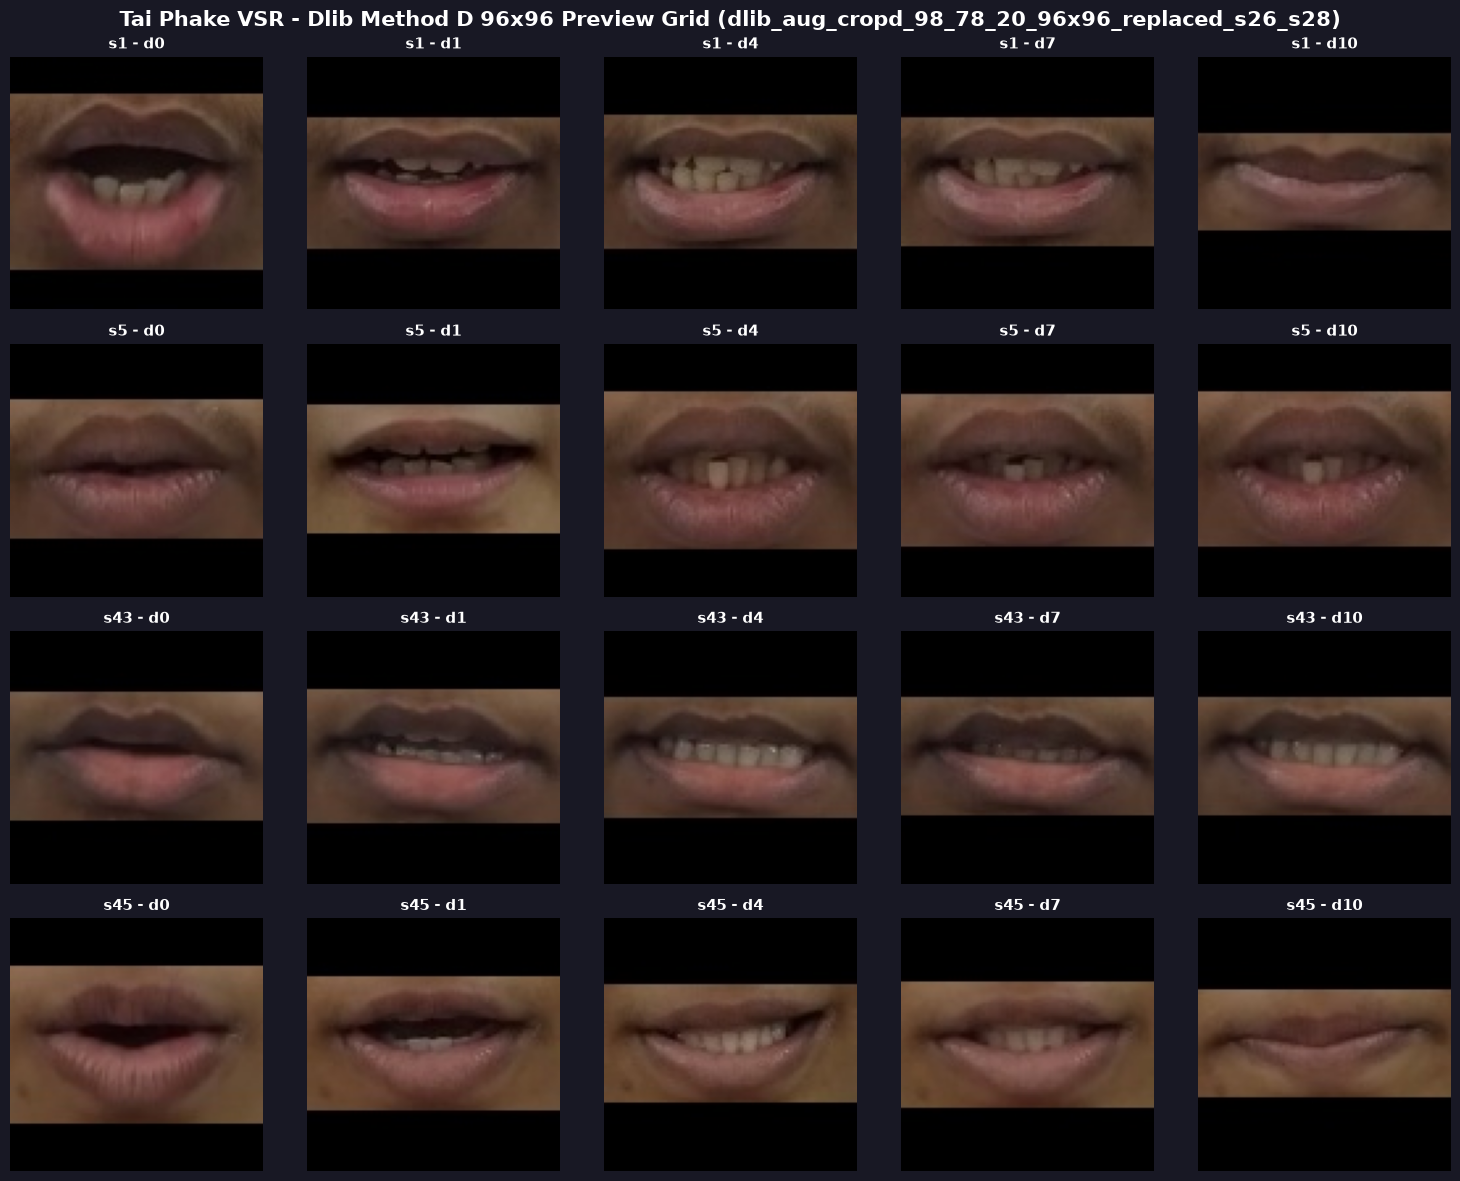

Preview grid saved: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/dlib_aug_cropd_98_78_20_96x96_replaced_s26_s28/augmented_samples_preview.png


In [8]:
# Section 8: Summary Metrics & Visual Preview Grid
train_df = df_manifest[df_manifest["split"] == "train"]
val_df = df_manifest[df_manifest["split"] == "val"]

summary = {
    "dataset_name": DATASET_NAME,
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
    "target_resolution": f"{TARGET_WIDTH}x{TARGET_HEIGHT}",
    "total_folders": len(df_manifest["folder_name"].unique()),
    "train_folders": len(train_df["folder_name"].unique()),
    "val_folders": len(val_df["folder_name"].unique()),
    "total_frames": len(df_manifest),
    "train_frames": len(train_df),
    "val_frames": len(val_df),
    "original_frames": len(df_manifest[~df_manifest["is_augmented"]]),
    "augmented_frames": len(df_manifest[df_manifest["is_augmented"]]),
    "dlib_landmark_success_rate": float((df_geom["status"] == "SUCCESS").mean()) if len(df_geom) else 1.0,
    "zero_leakage_verified": len(set(train_df["base_speaker"].unique()) & set(val_df["base_speaker"].unique())) == 0
}

with open(OUTPUT_DATASET_DIR / "augmentation_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
with open(RESULTS_DIR / "augmentation_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 80)
print("DATASET SUMMARY METRICS")
print("=" * 80)
for k, v in summary.items():
    print(f"{k:30s}: {v}")
print("=" * 80)

# Render Preview Grid (including new validation speakers s43 and s45)
preview_speakers = [TRAIN_BASE_SPEAKERS[0], TRAIN_BASE_SPEAKERS[4], "s43", "s45"]
preview_digits = ["d0", "d1", "d4", "d7", "d10"]

fig, axes = plt.subplots(len(preview_speakers), len(preview_digits), figsize=(15, 12))
fig.patch.set_facecolor("#181824")

for r_idx, spk in enumerate(preview_speakers):
    for c_idx, dig in enumerate(preview_digits):
        ax = axes[r_idx, c_idx]
        ax.set_facecolor("#12121c")
        dig_dir = OUTPUT_DATASET_DIR / spk / dig
        frames = sorted(list(dig_dir.glob("*.jpg"))) if dig_dir.exists() else []
        if frames:
            mid_frame = frames[len(frames) // 2]
            img = cv2.imread(str(mid_frame))
            if img is not None:
                img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                ax.imshow(img_rgb)
                ax.set_title(f"{spk} - {dig}", color="white", fontsize=11, fontweight="bold")
        ax.axis("off")

plt.suptitle(f"Tai Phake VSR - Dlib Method D 96x96 Preview Grid ({DATASET_NAME})", color="white", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
preview_path = RESULTS_DIR / "augmented_samples_preview.png"
plt.savefig(preview_path, dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()
print(f"Preview grid saved: {preview_path}")
